In [1]:
%%writefile /kaggle/working/prepare_dataset.py
"""
CircuitCoach AI - dataset preparation for ElectroCom61 (YOLO format).

What it does
1. Merges the original train/valid/test splits into one pool.
2. Checks every image (can it be opened?) and every label line
   (5 numbers, valid class id, box inside the image). Bad lines are dropped;
   polygon lines are converted to boxes; corrupt images are dropped.
3. Finds exact duplicates (same file bytes) and near-duplicates
   (64-bit difference hash), plus Roboflow copies of the same source photo.
4. Re-splits 75/15/10 by duplicate GROUP, so near-identical photos never
   end up on both sides of the train/test line. The split is stratified so
   rare classes still appear in val and test where possible.
5. Writes a clean YOLO dataset, data.yaml, audit.json and per_class_counts.csv.

Usage (Kaggle):
    python prepare_dataset.py                       # finds the dataset by itself
    python prepare_dataset.py --near-dup-bits 4     # stricter near-duplicate match
"""

import argparse
import csv
import hashlib
import json
import random
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import yaml
from PIL import Image

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
ORIG_SPLITS = ["train", "valid", "val", "test"]


# ---------------------------------------------------------------- helpers
def find_raw_root(search_root: Path) -> Path:
    yamls = sorted(search_root.rglob("data.yaml"))
    if not yamls:
        raise SystemExit(f"[error] no data.yaml found under {search_root}")
    return yamls[0].parent


def dhash64(path: Path) -> int:
    """64-bit difference hash: shrink to 9x8 grey, compare neighbours."""
    with Image.open(path) as im:
        g = im.convert("L").resize((9, 8), Image.Resampling.LANCZOS)
        a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


def md5(path: Path) -> str:
    return hashlib.md5(path.read_bytes()).hexdigest()


def source_key(name: str) -> str:
    """Roboflow names copies 'photo_jpg.rf.<hash>.jpg' - same photo, same key."""
    return name.split(".rf.")[0] if ".rf." in name else name


def parse_label_file(path: Path, nc: int, stats: Counter):
    """Return a list of clean 'cls cx cy w h' lines."""
    if not path.exists():
        stats["missing_label_files"] += 1
        return []
    clean = []
    for raw in path.read_text().splitlines():
        parts = raw.split()
        if not parts:
            continue
        try:
            cls = int(float(parts[0]))
            vals = [float(v) for v in parts[1:]]
        except ValueError:
            stats["bad_lines_not_numbers"] += 1
            continue
        if not 0 <= cls < nc:
            stats["bad_lines_class_id"] += 1
            continue
        if len(vals) == 4:
            cx, cy, w, h = vals
        elif len(vals) >= 6 and len(vals) % 2 == 0:  # polygon -> box
            xs, ys = vals[0::2], vals[1::2]
            x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
            cx, cy, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0
            stats["polygons_converted"] += 1
        else:
            stats["bad_lines_wrong_length"] += 1
            continue
        # clip to the image, then reject boxes that are empty or far outside
        x0, y0 = max(0.0, cx - w / 2), max(0.0, cy - h / 2)
        x1, y1 = min(1.0, cx + w / 2), min(1.0, cy + h / 2)
        if x1 - x0 <= 0.001 or y1 - y0 <= 0.001:
            stats["bad_lines_empty_or_outside"] += 1
            continue
        if (x1 - x0) < w - 0.02 or (y1 - y0) < h - 0.02:
            stats["boxes_clipped"] += 1
        cx, cy, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0
        clean.append(f"{cls} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
    return clean


class UnionFind:
    def __init__(self, n):
        self.p = list(range(n))

    def find(self, i):
        while self.p[i] != i:
            self.p[i] = self.p[self.p[i]]
            i = self.p[i]
        return i

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[rb] = ra


# ---------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--raw", type=Path, default=None,
                    help="folder holding data.yaml (default: search /kaggle/input)")
    ap.add_argument("--search-root", type=Path, default=Path("/kaggle/input"))
    ap.add_argument("--out", type=Path, default=Path("/kaggle/working/ec61_clean"))
    ap.add_argument("--near-dup-bits", type=int, default=6,
                    help="dHash Hamming distance counted as near-duplicate (lower = stricter)")
    ap.add_argument("--ratios", type=float, nargs=3, default=[0.75, 0.15, 0.10])
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args()

    raw = args.raw or find_raw_root(args.search_root)
    meta = yaml.safe_load((raw / "data.yaml").read_text())
    names = meta["names"]
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    nc = len(names)
    print(f"[scan] dataset root: {raw}")
    print(f"[scan] {nc} classes, first five: {names[:5]}")

    # 1. pool every image from every original split
    items = []
    for split in ORIG_SPLITS:
        img_dir = raw / split / "images"
        if not img_dir.is_dir():
            continue
        for p in sorted(img_dir.iterdir()):
            if p.suffix.lower() in IMG_EXTS:
                items.append({"img": p, "lbl": raw / split / "labels" / f"{p.stem}.txt",
                              "orig_split": split})
    print(f"[scan] {len(items)} images found")

    # 2. validate images and labels
    stats = Counter()
    kept = []
    for it in items:
        try:
            with Image.open(it["img"]) as im:
                im.verify()
            it["dhash"] = dhash64(it["img"])
            it["md5"] = md5(it["img"])
        except Exception:
            stats["corrupt_images_dropped"] += 1
            continue
        it["lines"] = parse_label_file(it["lbl"], nc, stats)
        if not it["lines"]:
            stats["images_without_boxes"] += 1
        kept.append(it)
    items = kept

    # 3a. exact duplicates: keep the first copy only
    seen, unique = {}, []
    for it in items:
        if it["md5"] in seen:
            stats["exact_duplicates_dropped"] += 1
            continue
        seen[it["md5"]] = True
        unique.append(it)
    items = unique
    n = len(items)

    # 3b. group near-duplicates and Roboflow copies of the same source photo
    uf = UnionFind(n)
    by_source = defaultdict(list)
    for i, it in enumerate(items):
        by_source[source_key(it["img"].name)].append(i)
    for idx in by_source.values():
        for j in idx[1:]:
            uf.union(idx[0], j)
            stats["same_source_links"] += 1

    hashes = np.array([it["dhash"] for it in items], dtype=np.uint64)
    near_pairs = 0
    for i in range(n - 1):
        x = np.bitwise_xor(hashes[i + 1:], hashes[i])
        dist = np.unpackbits(x.view(np.uint8)).reshape(-1, 64).sum(axis=1)
        for k in np.nonzero(dist <= args.near_dup_bits)[0]:
            uf.union(i, i + 1 + int(k))
            near_pairs += 1
    stats["near_duplicate_pairs"] = near_pairs

    groups = defaultdict(list)
    for i in range(n):
        groups[uf.find(i)].append(i)
    groups = list(groups.values())
    sizes = sorted((len(g) for g in groups), reverse=True)
    print(f"[dups] exact dropped={stats['exact_duplicates_dropped']} "
          f"near pairs={near_pairs} groups={len(groups)} largest_group={sizes[0]}")
    if sizes[0] > max(25, 0.02 * n):
        print(f"[warn] largest group holds {sizes[0]} images (>2% of data). Similar "
              f"backgrounds may be chaining photos together; re-run with --near-dup-bits 4")

    # 4. grouped, stratified 75/15/10 split
    split_names = ["train", "val", "test"]
    total_boxes = Counter()
    for it in items:
        for ln in it["lines"]:
            total_boxes[int(ln.split()[0])] += 1
    target = {s: {c: total_boxes[c] * r for c in total_boxes}
              for s, r in zip(split_names, args.ratios)}
    target_imgs = {s: n * r for s, r in zip(split_names, args.ratios)}
    have = {s: Counter() for s in split_names}
    have_imgs = Counter()

    def group_classes(g):
        cnt = Counter()
        for i in g:
            for ln in items[i]["lines"]:
                cnt[int(ln.split()[0])] += 1
        return cnt

    rng = random.Random(args.seed)
    rng.shuffle(groups)
    gcls = [group_classes(g) for g in groups]
    # rarest classes first, so they are spread across all three splits
    order = sorted(range(len(groups)),
                   key=lambda k: min((total_boxes[c] for c in gcls[k]), default=10**9))

    assignment = {}
    for k in order:
        g, cls = groups[k], gcls[k]

        def score(s):
            img_need = (target_imgs[s] - have_imgs[s]) / max(target_imgs[s], 1)
            if not cls:
                return img_need
            cls_need = sum((target[s][c] - have[s][c]) / max(target[s][c], 1e-9)
                           for c in cls) / len(cls)
            return cls_need + 0.5 * img_need

        s = max(split_names, key=score)
        assignment[k] = s
        have_imgs[s] += len(g)
        have[s].update(cls)

    # 5. write the clean dataset
    if args.out.exists():
        shutil.rmtree(args.out)
    used_names = set()
    for k, g in enumerate(groups):
        s = assignment[k]
        for i in g:
            it = items[i]
            name = it["img"].name
            if name in used_names:  # same file name in two original splits
                name = f"{it['orig_split']}_{name}"
            used_names.add(name)
            img_out = args.out / s / "images" / name
            lbl_out = args.out / s / "labels" / f"{Path(name).stem}.txt"
            img_out.parent.mkdir(parents=True, exist_ok=True)
            lbl_out.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(it["img"], img_out)
            lbl_out.write_text("\n".join(it["lines"]) + ("\n" if it["lines"] else ""))

    data_yaml = {"path": str(args.out.resolve()), "train": "train/images",
                 "val": "val/images", "test": "test/images",
                 "names": {i: nm for i, nm in enumerate(names)}}
    (args.out / "data.yaml").write_text(yaml.safe_dump(data_yaml, sort_keys=False))

    with open(args.out / "per_class_counts.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["class_id", "class_name", "train_boxes", "val_boxes", "test_boxes", "total"])
        for c, nm in enumerate(names):
            w.writerow([c, nm, have["train"][c], have["val"][c], have["test"][c], total_boxes[c]])

    missing_val = [names[c] for c in range(nc) if have["val"][c] == 0]
    missing_test = [names[c] for c in range(nc) if have["test"][c] == 0]
    audit = {
        "source": str(raw), "near_dup_bits": args.near_dup_bits, "seed": args.seed,
        "ratios": args.ratios, "images_scanned": len(kept) + stats["corrupt_images_dropped"],
        "images_written": n, "groups": len(groups), "largest_groups": sizes[:10],
        "split_images": dict(have_imgs),
        "split_boxes": {s: sum(have[s].values()) for s in split_names},
        "classes_missing_from_val": missing_val, "classes_missing_from_test": missing_test,
        "checks": dict(stats),
    }
    (args.out / "audit.json").write_text(json.dumps(audit, indent=2))

    # summary
    print(f"[done] wrote {n} images to {args.out}")
    print(f"       train {have_imgs['train']} | val {have_imgs['val']} | test {have_imgs['test']}")
    print(f"[checks] {dict(stats)}")
    rare = sorted(range(nc), key=lambda c: have["train"][c])[:10]
    print("[info] 10 classes with the fewest training boxes: "
          + ", ".join(f"{names[c]}={have['train'][c]}" for c in rare))
    print(f"[info] classes missing from val: {missing_val or 'none'}")
    print(f"[info] classes missing from test: {missing_test or 'none'}")
    print(f"[info] data.yaml -> {args.out / 'data.yaml'}")


if __name__ == "__main__":
    main()


Writing /kaggle/working/prepare_dataset.py


In [2]:
!nvidia-smi

Tue Nov 17 21:00:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
%pip install -q -U ultralytics huggingface_hub
import ultralytics
ultralytics.checks()
print("Ultralytics version:", ultralytics.__version__)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7190.0/8156.9 GB disk)
Ultralytics version: 8.4.215


In [4]:
from pathlib import Path

yamls = list(Path("/kaggle/input").rglob("data.yaml"))
print("data.yaml found at:", yamls)
RAW = yamls[0].parent

for split in ["train", "valid", "test"]:
    imgs = list((RAW / split / "images").glob("*"))
    lbls = list((RAW / split / "labels").glob("*.txt"))
    print(f"{split:5s}  images={len(imgs):5d}  labels={len(lbls):5d}")

data.yaml found at: [PosixPath('/kaggle/input/datasets/faiyazabdullah/electrocom61/ElectroCom61 A Multiclass Dataset for Detection of Electronic Components/ElectroCom-61_v2/data.yaml')]
train  images= 1478  labels= 1478
valid  images=  438  labels=  438
test   images=  205  labels=  205


In [5]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import whoami

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
print("Hugging Face user:", whoami(token=HF_TOKEN)["name"])

Hugging Face user: JatheelMHD


In [6]:
from ultralytics import YOLO
model = YOLO("yolo26n.pt")
model.info()

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)

In [7]:
!python /kaggle/working/prepare_dataset.py

[scan] dataset root: /kaggle/input/datasets/faiyazabdullah/electrocom61/ElectroCom61 A Multiclass Dataset for Detection of Electronic Components/ElectroCom-61_v2
[scan] 61 classes, first five: ['1-5-Volt-Battery', '3-3-Volt-Battery', '7-Segment-Display', '9-Volt-Battery', 'Arduino-Mega']
[scan] 2121 images found
[dups] exact dropped=0 near pairs=17 groups=2104 largest_group=3
[done] wrote 2121 images to /kaggle/working/ec61_clean
       train 1569 | val 322 | test 230
[checks] {'near_duplicate_pairs': 17}
[info] 10 classes with the fewest training boxes: RFID-Scanner=113, 9-Volt-Battery=119, LDR-Sensor=121, TCRT5000=123, Buck-Converter=125, Resistor=125, Pin-Header=126, DC-Motor=127, Taper-Potentiometer=128, FT-232-USB-Serial-Module=130
[info] classes missing from val: none
[info] classes missing from test: none
[info] data.yaml -> /kaggle/working/ec61_clean/data.yaml


In [8]:
import json, pandas as pd
audit = json.load(open("/kaggle/working/ec61_clean/audit.json"))
print(json.dumps(audit, indent=2))
pd.read_csv("/kaggle/working/ec61_clean/per_class_counts.csv").sort_values("train_boxes").head(15)

{
  "source": "/kaggle/input/datasets/faiyazabdullah/electrocom61/ElectroCom61 A Multiclass Dataset for Detection of Electronic Components/ElectroCom-61_v2",
  "near_dup_bits": 6,
  "seed": 0,
  "ratios": [
    0.75,
    0.15,
    0.1
  ],
  "images_scanned": 2121,
  "images_written": 2121,
  "groups": 2104,
  "largest_groups": [
    3,
    2,
    2,
    2,
    2,
    2,
    2,
    2,
    2,
    2
  ],
  "split_images": {
    "train": 1569,
    "val": 322,
    "test": 230
  },
  "split_boxes": {
    "train": 9694,
    "val": 1949,
    "test": 1294
  },
  "classes_missing_from_val": [],
  "classes_missing_from_test": [],
  "checks": {
    "near_duplicate_pairs": 17
  }
}


,class_id,class_name,train_boxes,val_boxes,test_boxes,total
47,47,RFID-Scanner,113,24,16,153
3,3,9-Volt-Battery,119,24,17,160
36,36,LDR-Sensor,121,23,17,161
55,55,TCRT5000,123,25,17,165
50,50,Resistor,125,26,18,169
11,11,Buck-Converter,125,26,17,168
45,45,Pin-Header,126,27,18,171
15,15,DC-Motor,127,26,18,171
57,57,Taper-Potentiometer,128,26,18,172
52,52,Servo-Motor,130,27,17,174


In [9]:
from pathlib import Path
from ultralytics import YOLO

DATA = "/kaggle/working/ec61_clean/data.yaml"
WORK = "/kaggle/working"
RUN_NAME = "yolo26n_ec61_v2"

model = YOLO("yolo26n.pt")
model.train(
    data=DATA, imgsz=640, epochs=100, patience=0, batch=32,
    degrees=10, flipud=0.5, seed=0, deterministic=True,
    project=f"{WORK}/runs", name=RUN_NAME, exist_ok=True,
    device=0, workers=2, plots=True,
)
SAVE_DIR = Path(model.trainer.save_dir)
print("Saved to:", SAVE_DIR)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/ec61_clean/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_ec61_v2, nbs=64, nms=None, opset=None, optim

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100       6.5G      1.451      10.63    0.01303         21        640: 100% ━━━━━━━━━━━━ 50/50 3.4it/s 14.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.5it/s 2.4s
                   all        322       1949      0.269      0.183      0.105     0.0636

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/100       6.5G      1.351       5.94    0.01248          6        640: 100% ━━━━━━━━━━━━ 50/50 3.3it/s 15.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.3it/s 2.6s
                   all        322       1949       0.44      0.379      0.365      0.201

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      4/100       6.5G      1.327      4.392    0.01328          1        640: 100% ━━━━━━━━━━━━ 50/50 3.0it/s 16.5s
                 Class     Images  Instances      Box(P        

Epochs run: 100 | best epoch: 100
Val  P=0.935  R=0.937  mAP50=0.958  mAP50-95=0.624


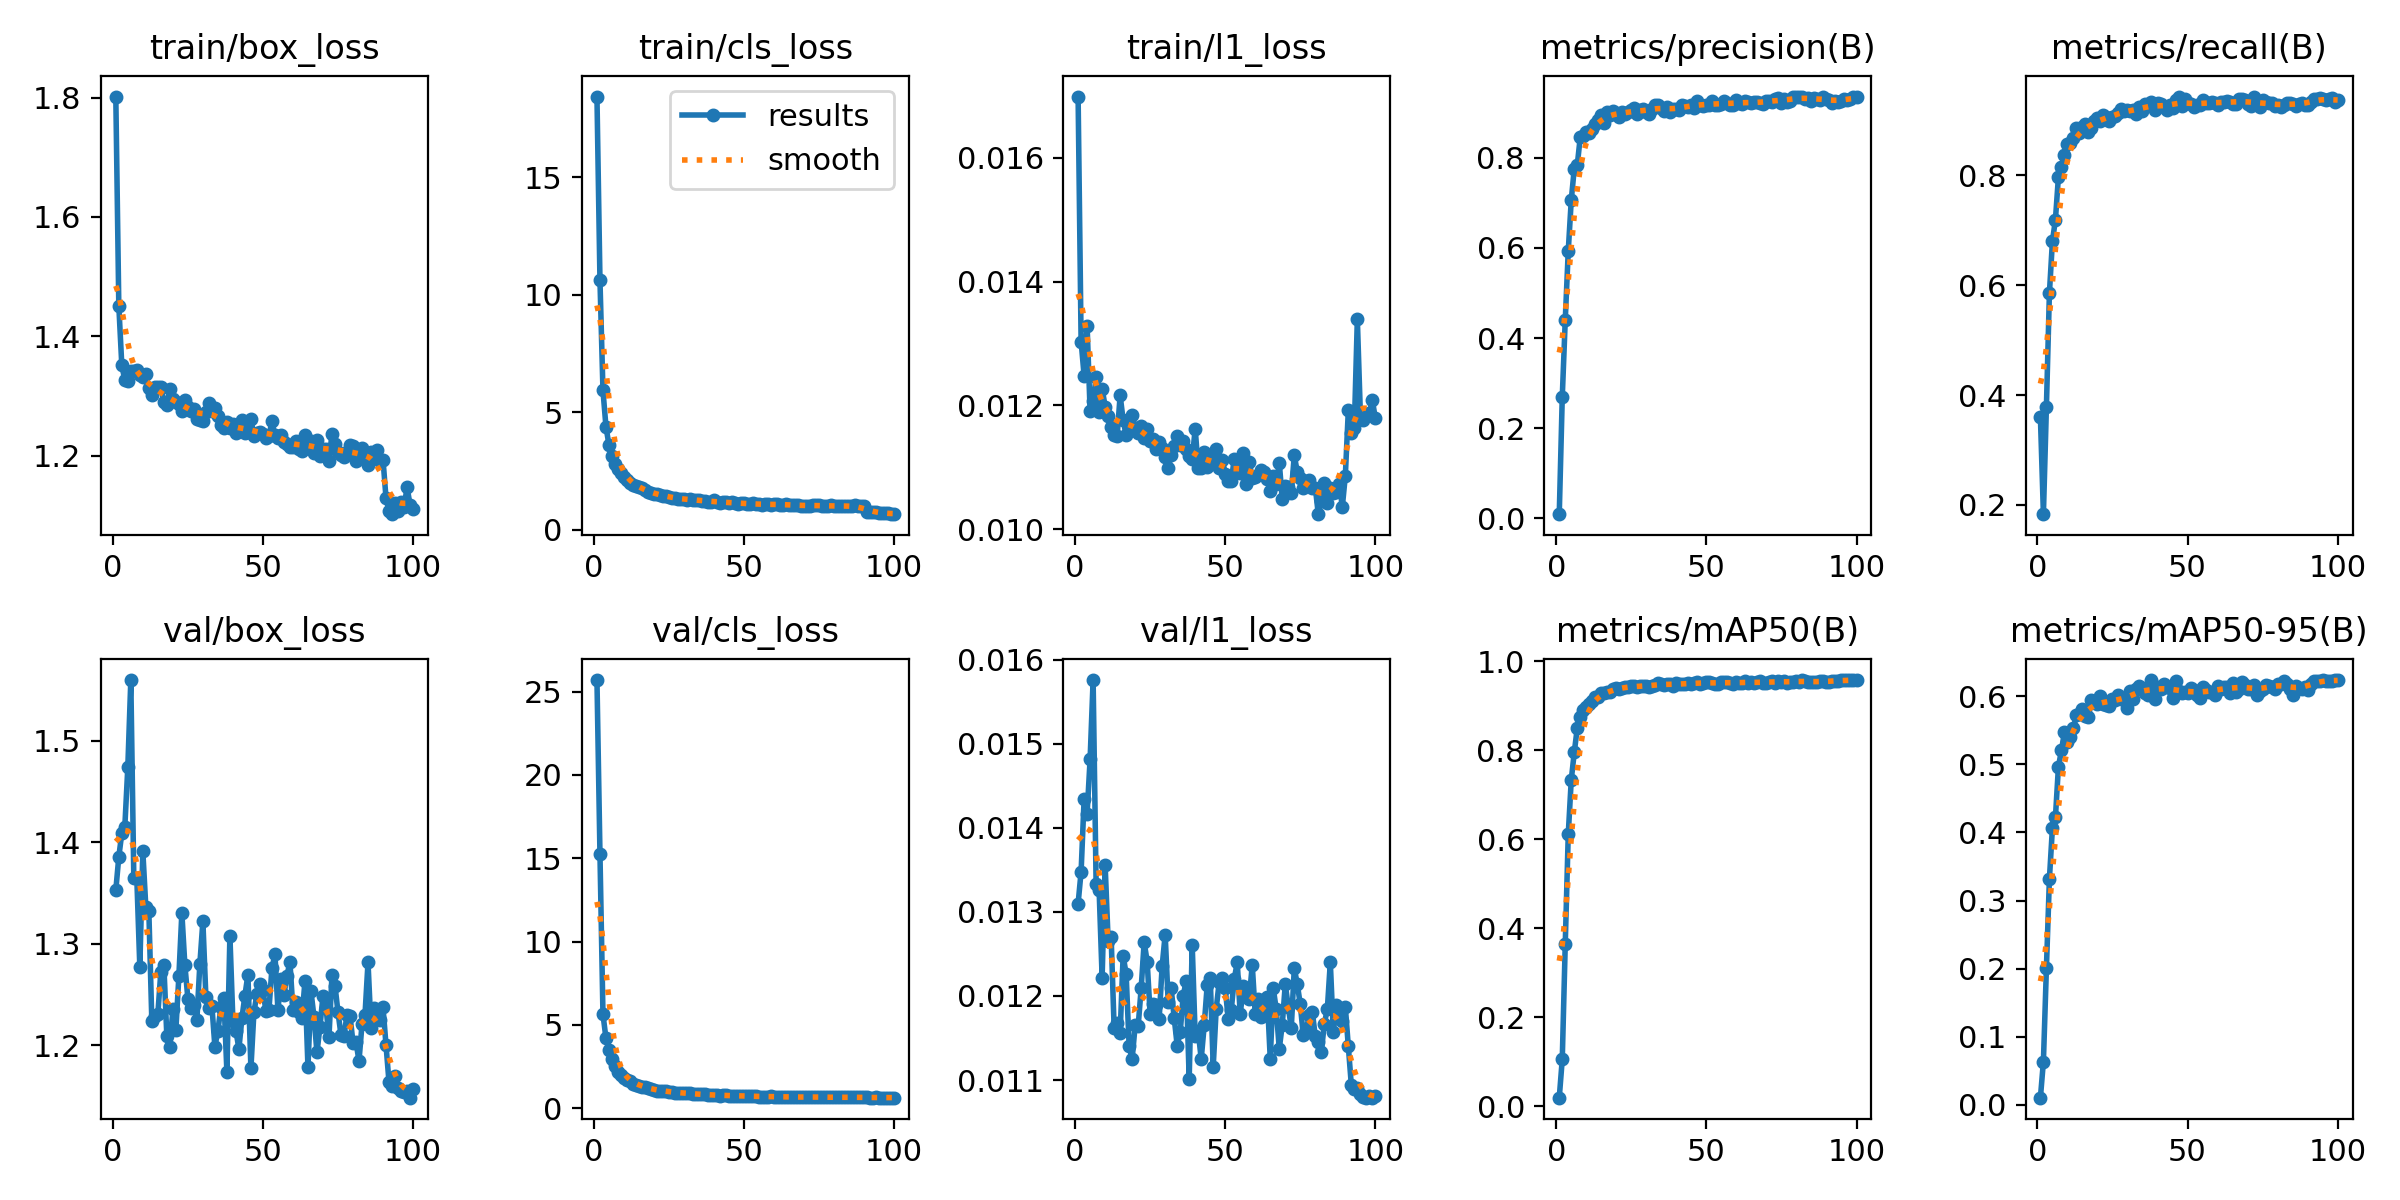

In [10]:
import pandas as pd
from IPython.display import Image, display

df = pd.read_csv(SAVE_DIR / "results.csv")
df.columns = df.columns.str.strip()
best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
print(f"Epochs run: {len(df)} | best epoch: {int(best['epoch'])}")
print(f"Val  P={best['metrics/precision(B)']:.3f}  R={best['metrics/recall(B)']:.3f}  "
      f"mAP50={best['metrics/mAP50(B)']:.3f}  mAP50-95={best['metrics/mAP50-95(B)']:.3f}")
display(Image(filename=str(SAVE_DIR / "results.png"), width=1000))